In [1]:
import sys
sys.path.append("./../") 

import numpy as np
import random

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from scipy.stats import weightedtau

from scripts.utils import load_array

This notebook contains code for analyzing and visualizing the difference in SHAP values between the concept agnostic and concept informed model types. For comparison models of the same type are also compared.

In [2]:
# Set random seeds for reproducability
np.random.seed(12)
random.seed(12)

In [3]:
colors = ["#A338C4", '#248EF1', "#29BA10", '#F68D0E', '#F12476']

In [4]:
datasets = ['opportunity_uni', 'fordA', 'turbofan']

In [5]:
# Used for storing results for all datasets and both metrics
result_dict = {d: {t: {m: [[]] * 5 for m in ['taus', 'rmse']} 
               for t in ['agnostic-specific', 'agnostic-agnostic', 'specific-specific']} 
               for d in datasets}

In [6]:
def compare(shap_path1, shap_path2, base_path1, base_path2, task):
    """
    Compare sets of SHAP values
    shap_path1: path to first set of SHAP values for n samples
    shap_path2: path to second set of SHAP values for the same n samples
    base_path1: parth to corresponding first set of base values
    base_path2: parth to corresponding second set of base values
    task: task of predictive model, classification or regression
    returns: weighted taus and RMSE for all samples in the given sets of SHAP values
    """
    # Load SHAP values
    shap_values1 = load_array(shap_path1)
    shap_values1 = np.squeeze(np.array(shap_values1))

    shap_values2 = load_array(shap_path2)
    shap_values2 = np.squeeze(np.array(shap_values2))

    # Normalize SHAP values
    shap_values1_norm = (shap_values1 - np.mean(shap_values1)) / np.std(shap_values1)
    shap_values2_norm = (shap_values2 - np.mean(shap_values2)) / np.std(shap_values2)

    # Load base values to determine model prediction
    base_values1 = np.squeeze(load_array(base_path1))

    if task == 'classification':
        # Determine model prediction to select correct set of SHAP values
        y_logits = np.sum(shap_values1, axis=1) + base_values1
        y_pred = np.argmax(y_logits, axis=1)

        # Determine weighted taus of SHAP value pair
        weightedtaus = [weightedtau(np.abs(s1[:, y]), np.abs(s2[:, y])).statistic \
            for s1, s2, y in zip(shap_values1_norm, shap_values2_norm, y_pred)]
    else:
        # Determine model prediction to select correct set of SHAP values
        y_pred = np.sum(shap_values1, axis=1) + base_values1

        # Determine weighted taus of SHAP value pair
        weightedtaus = [weightedtau(np.abs(s1), np.abs(s2)).statistic \
            for s1, s2 in zip(shap_values1_norm, shap_values2_norm)]

    # Determine RMSE of SHAP value sets
    rmse = [np.sqrt(np.mean((s1 - s2) ** 2)) for s1, s2 in zip(shap_values1_norm, shap_values2_norm)]
    return weightedtaus, rmse

In [7]:
for dataset in datasets:
    # Initialize information
    if dataset in ['opportunity_uni', 'fordA']:
        task = 'classification'
    else:
        task = 'regression'

    if dataset in ['opportunity_uni', 'turbofan']:
        decomposition_def = 'trend+bias+scale*(low_freq+var*high_freq)'
    else:
        decomposition_def = 'scale*(low_freq+var*high_freq)'

    # Determine paths
    shap_path = './../data/cshap/' + dataset + '/uni_channel/' + decomposition_def
    shap_path = shap_path.replace('*', 'x')
    shap_path_multi = './../data/cshap/' + dataset + '/multi_channel/' + decomposition_def
    shap_path_multi = shap_path_multi.replace('*', 'x')

    model_path = './../models/' + dataset + '/uni_channel'
    model_path = model_path.replace('*', 'x')
    model_path_multi = './../models/' + dataset + '/' + decomposition_def
    model_path_multi = model_path_multi.replace('*', 'x')

    # Concept agnostic vs concept informed
    # Determine which models to compare (5 randomly selected out of the 10 we have trained)
    selection1 = random.sample(list(range(10)), 5)
    selection2 = random.sample(list(range(10)), 5)
    for i in range(5):          # Iterate through the 5 pairs
            idx1 = selection1[i]
            idx2 = selection2[i]

            # Load paths based on selected models
            shap_path1 = shap_path + '/shap_values' + str(idx1) + '.pkl'
            shap_path2 = shap_path_multi + '/shap_values' + str(idx2) + '.pkl'

            base_path1 = shap_path + '/base_values' + str(idx1) + '.pkl'
            base_path2 = shap_path_multi + '/base_values' + str(idx2) + '.pkl'
            
            # Do pairwise sample comparisons
            weightedtaus, rmse = compare(shap_path1, shap_path2, base_path1, base_path2, task)

            # Store results
            result_dict[dataset]['agnostic-specific']['taus'][i] = weightedtaus
            result_dict[dataset]['agnostic-specific']['rmse'][i] = rmse

    # Concept informed vs concept informed
    # Determine which models to compare randomly split the 10 trained models into 2 groups
    shuffling = random.sample(list(range(10)), 10)
    selection1 = shuffling[:5]
    selection2 = shuffling[5:]
    for i in range(5):          # Iterate through the 5 pairs
            idx1 = selection1[i]
            idx2 = selection2[i]

            # Load paths based on selected models
            shap_path1 = shap_path_multi + '/shap_values' + str(idx1) + '.pkl'
            shap_path2 = shap_path_multi + '/shap_values' + str(idx2) + '.pkl'

            base_path1 = shap_path_multi + '/base_values' + str(idx1) + '.pkl'
            base_path2 = shap_path_multi + '/base_values' + str(idx2) + '.pkl'
            
            # Do pairwise sample comparisons
            weightedtaus, rmse = compare(shap_path1, shap_path2, base_path1, base_path2, task)

            # Store results
            result_dict[dataset]['specific-specific']['taus'][i] = weightedtaus
            result_dict[dataset]['specific-specific']['rmse'][i] = rmse

    # Concept agnostic vs concept agnostic
    # Determine which models to compare randomly split the 10 trained models into 2 groups
    shuffling = random.sample(list(range(10)), 10)
    selection1 = shuffling[:5]
    selection2 = shuffling[5:]
    for i in range(5):          # Iterate through the 5 pairs
            idx1 = selection1[i]
            idx2 = selection2[i]

            # Load paths based on selected models
            shap_path1 = shap_path + '/shap_values' + str(idx1) + '.pkl'
            shap_path2 = shap_path + '/shap_values' + str(idx2) + '.pkl'

            base_path1 = shap_path + '/base_values' + str(idx1) + '.pkl'
            base_path2 = shap_path + '/base_values' + str(idx2) + '.pkl'

            # Do pairwise sample comparisons
            weightedtaus, rmse = compare(shap_path1, shap_path2, base_path1, base_path2, task)

            # Store results
            result_dict[dataset]['agnostic-agnostic']['taus'][i] = weightedtaus
            result_dict[dataset]['agnostic-agnostic']['rmse'][i] = rmse

In [8]:
# Calculate means over 5 model pairs
mean_dict = {m: {t: {d: np.mean(sub_d, axis=0) 
                        for d, sub_d in sub_t.items()} 
                        for t, sub_t in sub_m.items()} 
                        for m, sub_m in result_dict.items()}

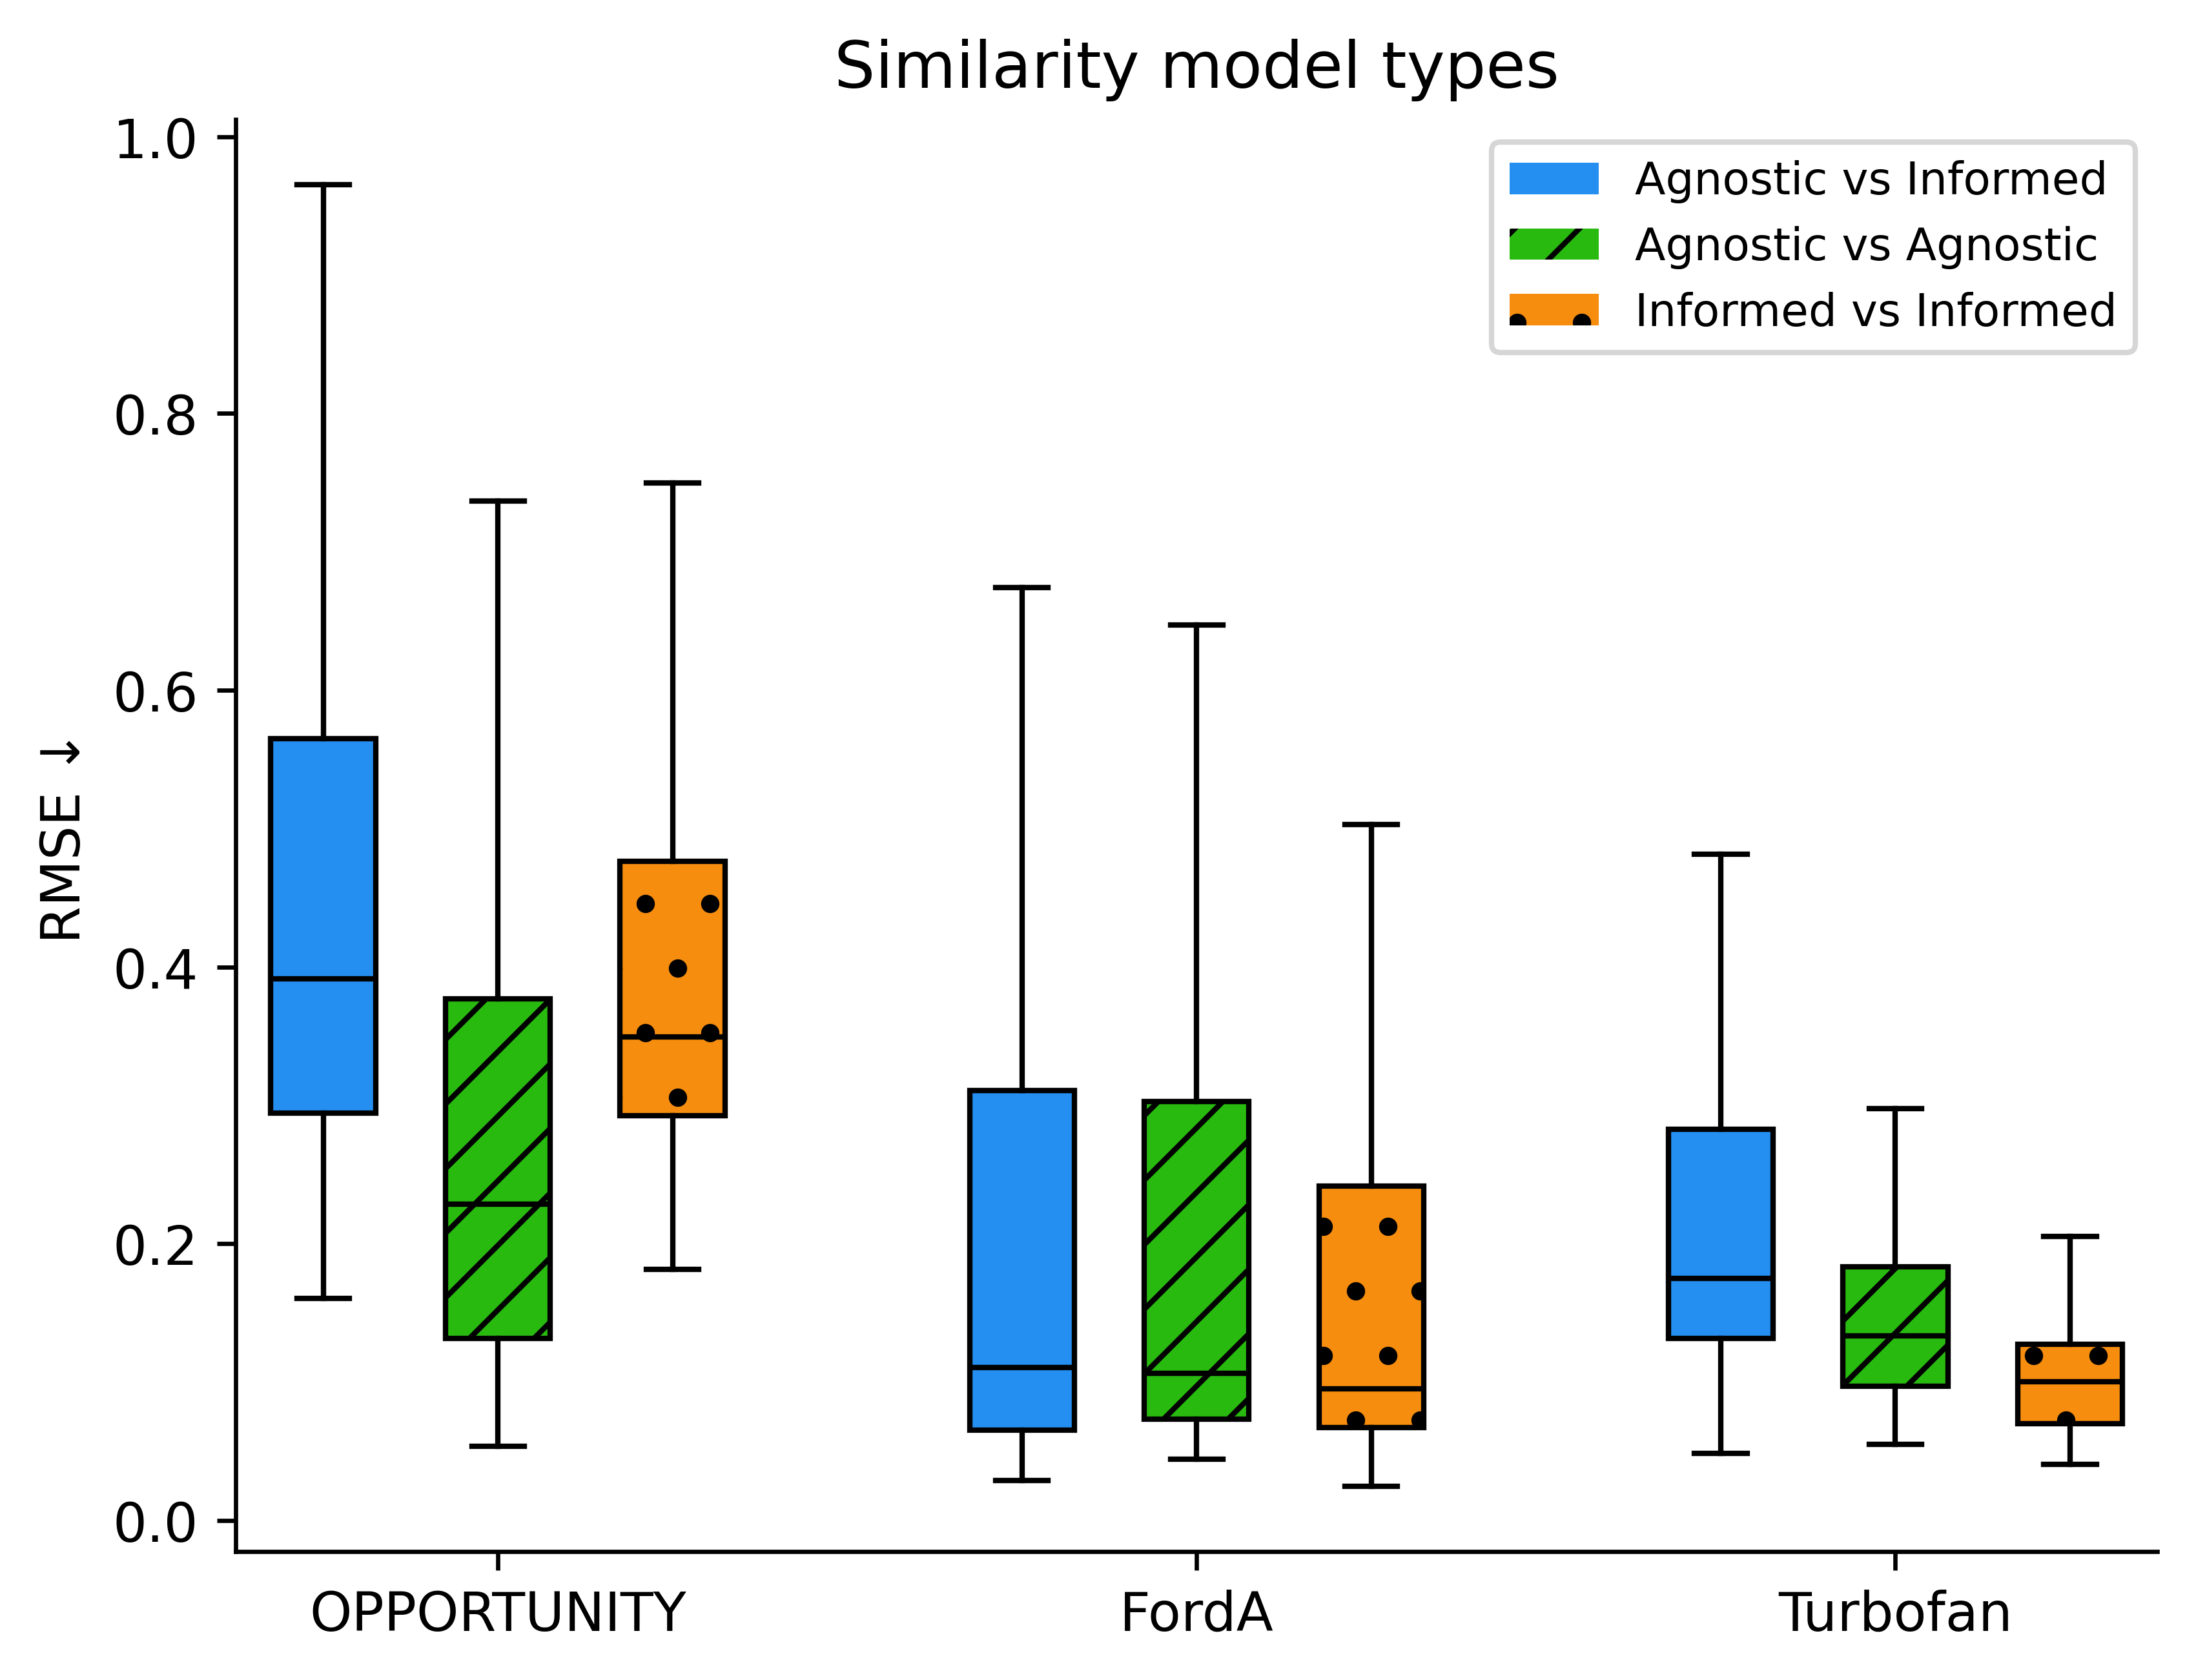

In [9]:
# Initialize figure
fig, ax = plt.subplots(dpi=600)

# Create boxplot per dataset
boxplot_opp = ax.boxplot([mean_dict['opportunity_uni']['agnostic-specific']['rmse'], 
                          mean_dict['opportunity_uni']['agnostic-agnostic']['rmse'],
                          mean_dict['opportunity_uni']['specific-specific']['rmse']
                          ], 
                      positions=np.array(range(3)),  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_fordA = ax.boxplot([mean_dict['fordA']['agnostic-specific']['rmse'], 
                          mean_dict['fordA']['agnostic-agnostic']['rmse'],
                          mean_dict['fordA']['specific-specific']['rmse']], 
                      positions=np.array(range(3)) + 4,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_tf = ax.boxplot([mean_dict['turbofan']['agnostic-specific']['rmse'], 
                          mean_dict['turbofan']['agnostic-agnostic']['rmse'],
                          mean_dict['turbofan']['specific-specific']['rmse']],  
                      positions=np.array(range(3)) + 8,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

# Add hatches and colors to barplots
hatches = [None, '//', '.']
sub_colors = [colors[1], colors[2], colors[3]]
for patch, color, hatch in zip(boxplot_opp['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

for patch, color, hatch in zip(boxplot_fordA['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

for patch, color, hatch in zip(boxplot_tf['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

# Put dataset names as x ticks
ax.set_xticks([1, 5, 9])
ax.set_xticklabels(['OPPORTUNITY', 'FordA', 'Turbofan'])

# Set legend
legend_elements = [
                    Patch(facecolor=colors[1], label='Agnostic vs Informed'),
                    Patch(facecolor=colors[2], label='Agnostic vs Agnostic', hatch='//'),
                    Patch(facecolor=colors[3], label='Informed vs Informed', hatch='.')]

# Annotate figure
ax.set_title('Similarity model types')
ax.set_ylabel('RMSE ↓')
ax.legend(handles=legend_elements, loc='upper right', fontsize='small')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)

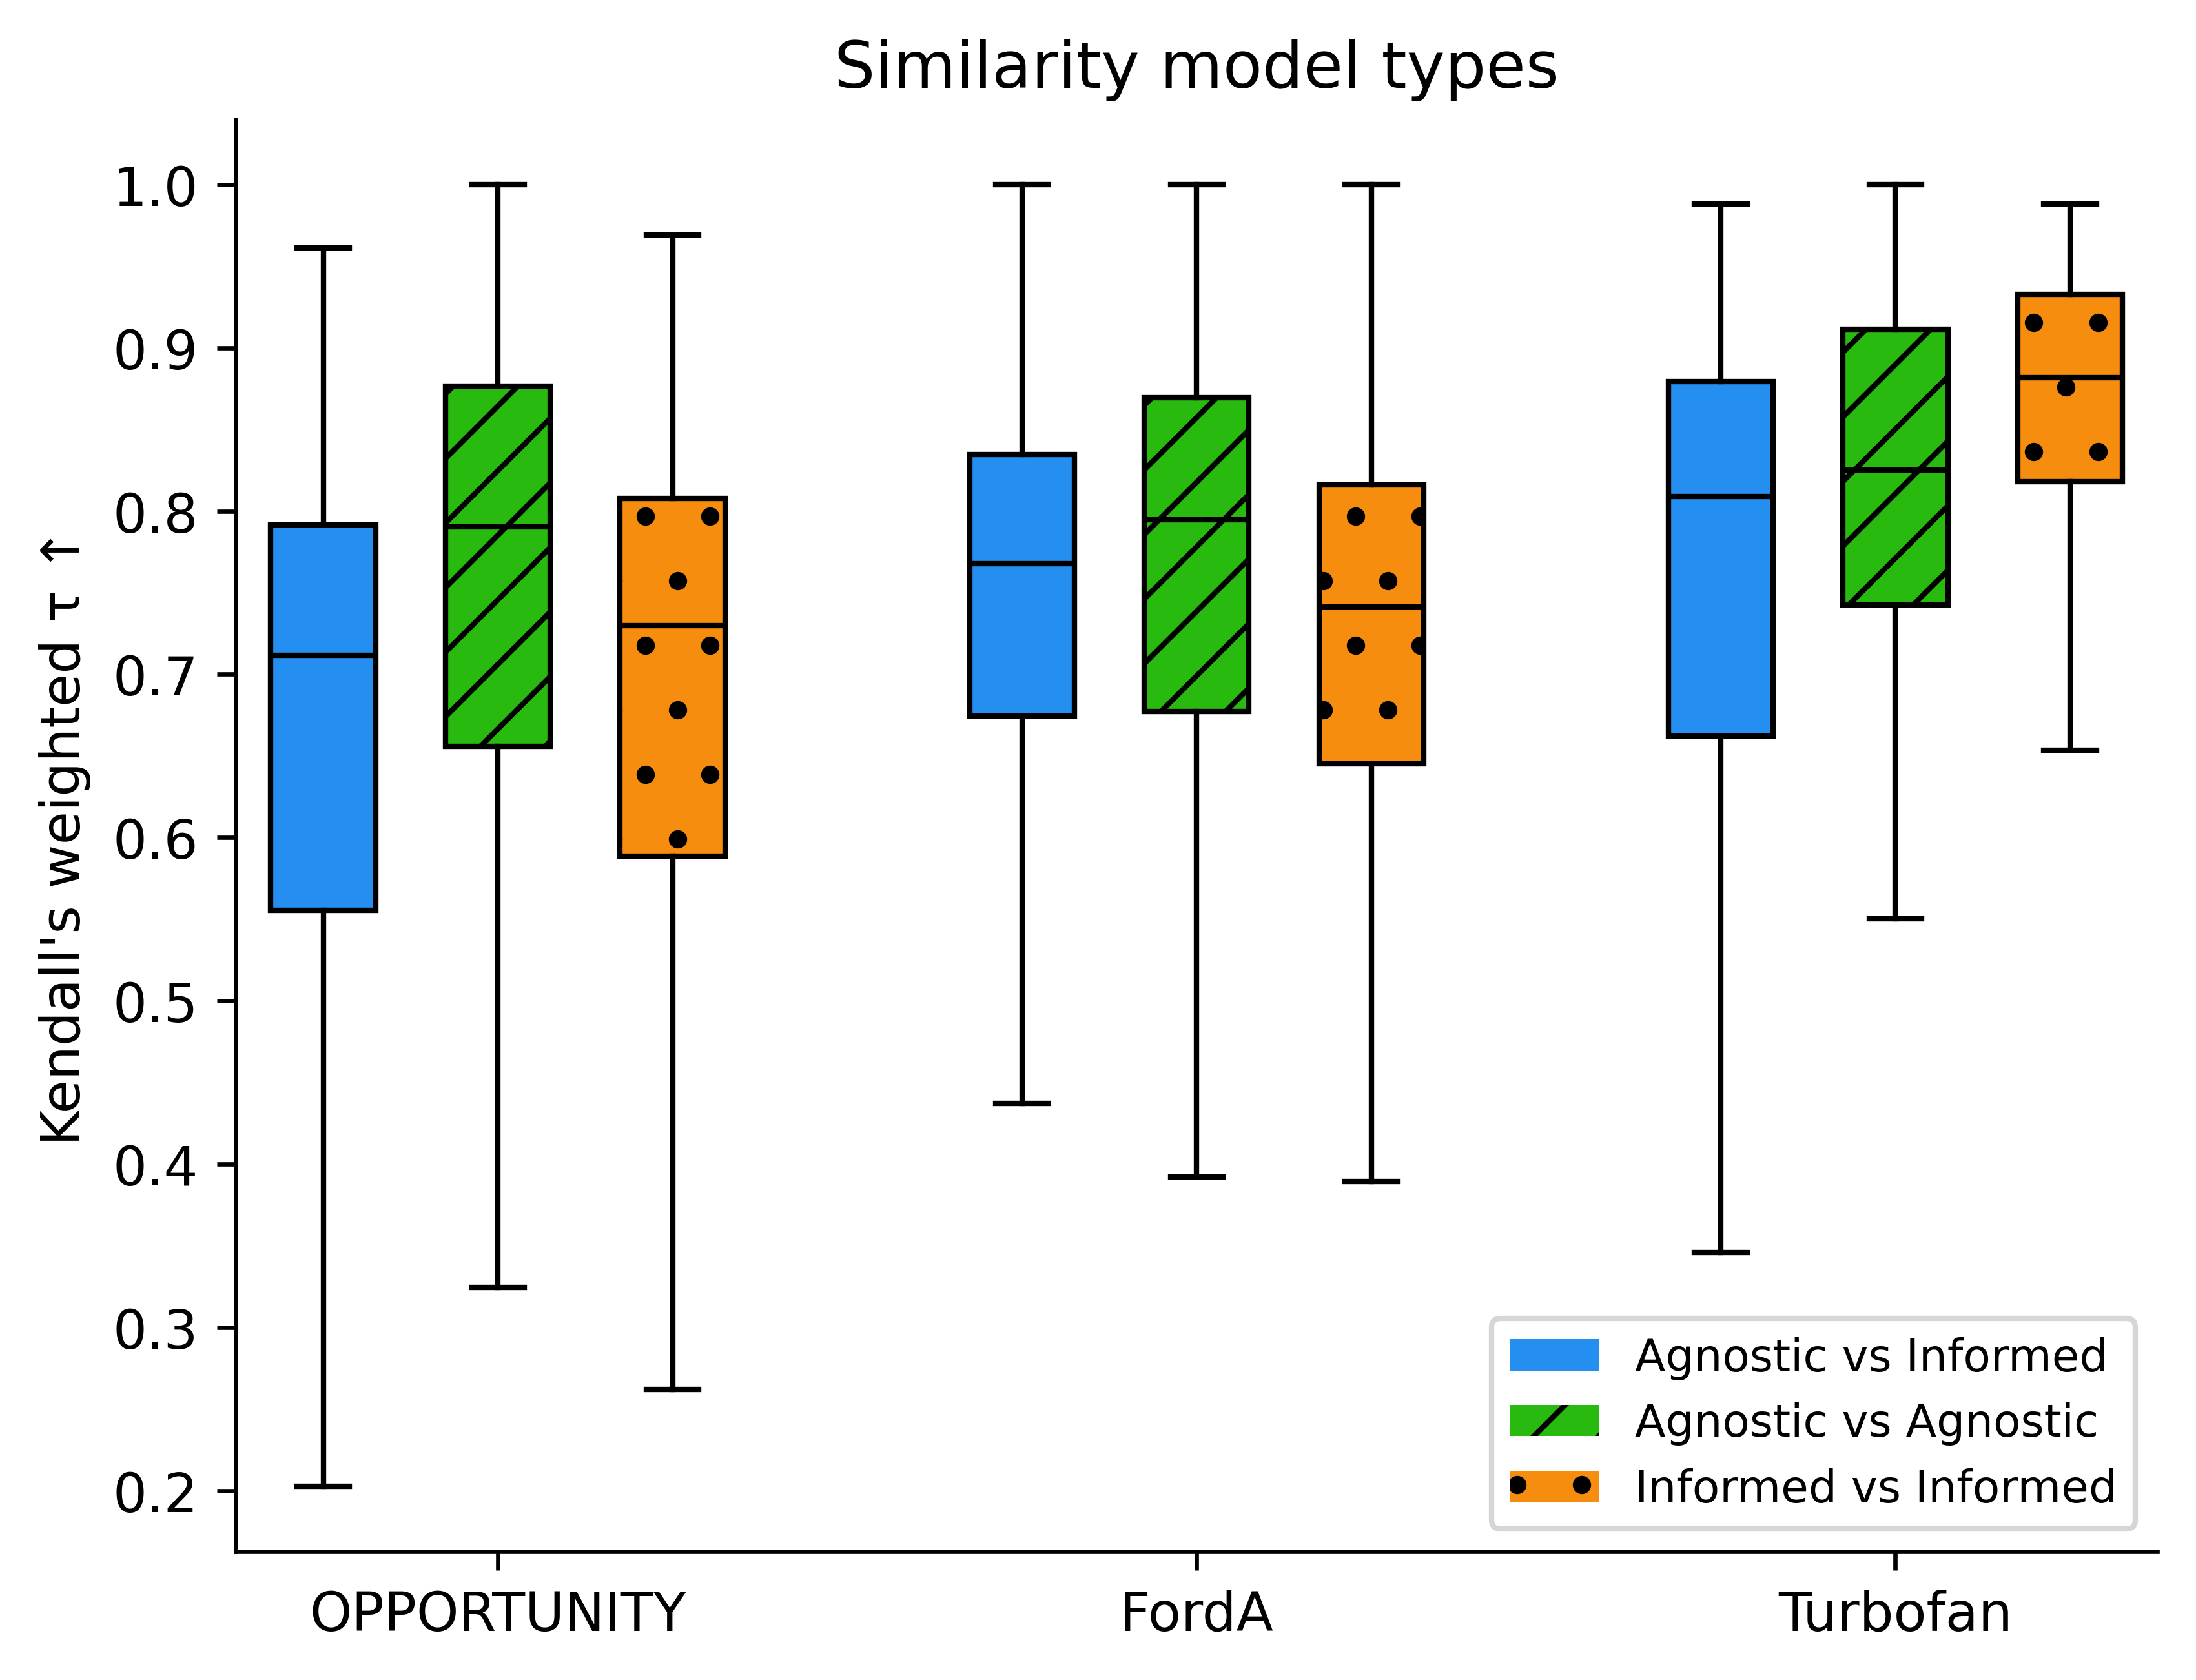

In [10]:
# Initialize figure
fig, ax = plt.subplots(dpi=600)

# Create boxplot per dataset
boxplot_opp = ax.boxplot([mean_dict['opportunity_uni']['agnostic-specific']['taus'], 
                          mean_dict['opportunity_uni']['agnostic-agnostic']['taus'],
                          mean_dict['opportunity_uni']['specific-specific']['taus']
                          ], 
                      positions=np.array(range(3)),  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_fordA = ax.boxplot([mean_dict['fordA']['agnostic-specific']['taus'], 
                          mean_dict['fordA']['agnostic-agnostic']['taus'],
                          mean_dict['fordA']['specific-specific']['taus']], 
                      positions=np.array(range(3)) + 4,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

boxplot_tf = ax.boxplot([mean_dict['turbofan']['agnostic-specific']['taus'], 
                          mean_dict['turbofan']['agnostic-agnostic']['taus'],
                          mean_dict['turbofan']['specific-specific']['taus']],  
                      positions=np.array(range(3)) + 8,  
                      widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color='black'))

# Add hatches and colors to barplots
hatches = [None, '//', '.']
sub_colors = [colors[1], colors[2], colors[3]]
for patch, color, hatch in zip(boxplot_opp['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

for patch, color, hatch in zip(boxplot_fordA['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

for patch, color, hatch in zip(boxplot_tf['boxes'], sub_colors, hatches):
    patch.set_facecolor(color)
    patch.set_hatch(hatch)

# Put dataset names as x ticks
ax.set_xticks([1, 5, 9])
ax.set_xticklabels(['OPPORTUNITY', 'FordA', 'Turbofan'])

# Set legend
legend_elements = [Patch(facecolor=colors[1], label='Agnostic vs Informed'),
                    Patch(facecolor=colors[2], label='Agnostic vs Agnostic', hatch='//'),
                    Patch(facecolor=colors[3], label='Informed vs Informed', hatch='.')]

# Annotate figure
ax.set_title('Similarity model types')
ax.set_ylabel('Kendall\'s weighted τ ↑')
ax.legend(handles=legend_elements, loc='lower right', fontsize='small')

# Remove spines
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)